# Freight rate prediction

Goal: predict `posted_rate` for the 12,000 unlabeled loads in `validation.csv` (Nov-Dec 2025),
learning from the 48,000 labeled loads in `train-test.csv` (Jan-Oct 2025).

In [1]:
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.compose import TransformedTargetRegressor
from sklearn.ensemble import HistGradientBoostingRegressor, RandomForestRegressor
from sklearn.linear_model import Ridge
from sklearn.model_selection import KFold
from sklearn.neural_network import MLPRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import RobustScaler, StandardScaler
from sklearn.svm import SVR

ROOT = Path.cwd() if (Path.cwd() / 'src').exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT / 'src'))
import features as F

warnings.filterwarnings('ignore')
pd.set_option('display.width', 200)

train = pd.read_csv(ROOT / 'data' / 'train-test.csv', parse_dates=['date'])
valid = pd.read_csv(ROOT / 'data' / 'validation.csv', parse_dates=['date'])
print(len(train), 'labeled rows,', len(valid), 'rows to predict')

48000 labeled rows, 12000 rows to predict


## 1. Data quality: issues and fixes

In [2]:
quality = pd.DataFrame({
    'train': [train.weight.isna().sum(), (train.weight < 0).sum(), train.market_index.isna().sum()],
    'validation': [valid.weight.isna().sum(), (valid.weight < 0).sum(), valid.market_index.isna().sum()],
}, index=['missing weight', 'negative weight', 'missing market_index'])
display(quality)

unseen = set(valid.pickup) | set(valid.delivery)
unseen -= set(train.pickup) | set(train.delivery)
share = (valid.pickup.isin(unseen) | valid.delivery.isin(unseen)).mean()
print(f'{len(unseen)} cities exist only in validation ({share:.0%} of its rows)')

,train,validation
missing weight,300,165
negative weight,292,145
missing market_index,374,249


8 cities exist only in validation (12% of its rows)



| Issue | Evidence | Treatment |
|---|---|---|
| Missing `weight` | Rate, distance and equipment mix match the other rows, so the gaps appear random | Filled with the median weight |
| Negative `weight` | Range and rate match the positive weights, indicating sign errors | Absolute value used |
| Missing `market_index` | One value per day, shared by all loads of that day (115 or more per day) | Filled with the mean of the same date (no labels used). The final model does not use this column |
| Cities only in validation | 8 cities, 12% of rows | Cities described by latitude and longitude instead of one-hot encoding |
| Unusual rates | Rate 2x to 5x above or below the usual rate for the same kind of load (see below) | Left out of training |

**Scaling.** Inputs are passed through a `RobustScaler` (median and IQR, which limits the influence of outliers).
The target is `sqrt(rate per mile)`, standardized to mean 0 and standard deviation 1.
Rate per mile decreases with distance, so predicting it and multiplying by distance
is more direct than predicting the dollar rate.


outliers: 677 rows (1.4%), 340 above and 337 below the expected rate


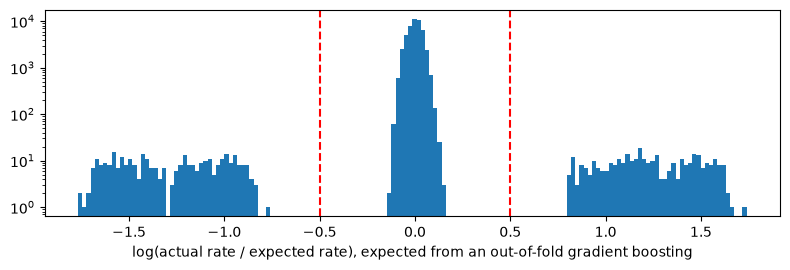

In [3]:
daily = F.daily_market(train, valid)
is_outlier, log_ratio = F.outlier_mask(train, daily)
train['outlier'] = is_outlier
train['rate_per_mile'] = train.posted_rate / train.distance

print(f'outliers: {is_outlier.sum()} rows ({is_outlier.mean():.1%}),',
      f'{(log_ratio[is_outlier] > 0).sum()} above and {(log_ratio[is_outlier] < 0).sum()} below the expected rate')

fig, ax = plt.subplots(figsize=(8, 2.8))
ax.hist(log_ratio, bins=160)
ax.axvline(0.5, color='red', linestyle='--')
ax.axvline(-0.5, color='red', linestyle='--')
ax.set_yscale('log')
ax.set_xlabel('log(actual rate / expected rate), expected from an out-of-fold gradient boosting')
plt.tight_layout()
plt.show()


The expected rate of each row comes from a gradient boosting model that did not see that row (5-fold).
A gap separates normal loads (standard deviation 0.036 in log terms) from outliers
(|log ratio| above 0.77), so the result is insensitive to the 0.5 threshold.
None of the inputs indicated which loads are outliers, so they are left out of training and
of the "clean" scores, and reported separately.


## 2. Key findings from the data

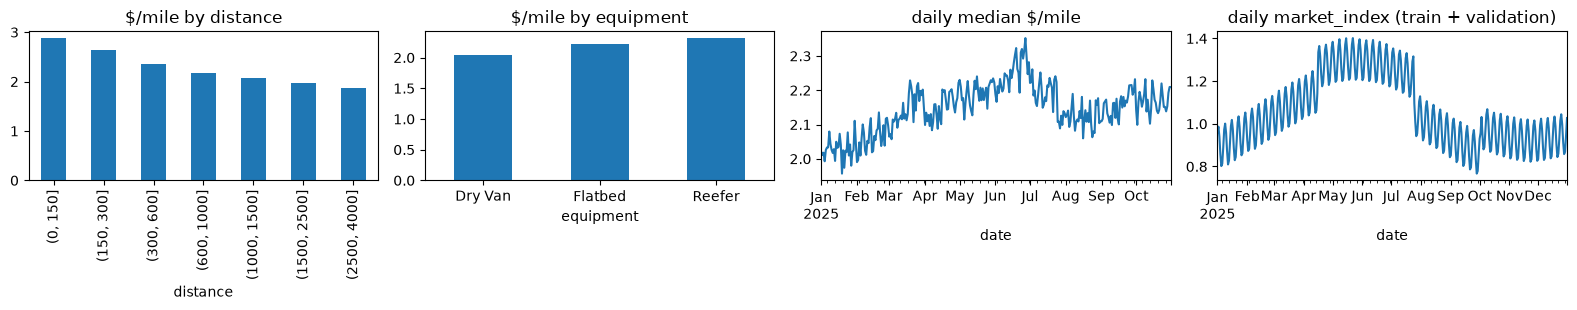

In [4]:
clean = train[~train.outlier].reset_index(drop=True)

fig, ax = plt.subplots(1, 4, figsize=(16, 3.2))
distance_bins = pd.cut(clean.distance, [0, 150, 300, 600, 1000, 1500, 2500, 4000])
clean.groupby(distance_bins, observed=True).rate_per_mile.median().plot.bar(ax=ax[0], title='$/mile by distance')
clean.groupby('equipment').rate_per_mile.median().plot.bar(ax=ax[1], title='$/mile by equipment', rot=0)
clean.groupby('date').rate_per_mile.median().plot(ax=ax[2], title='daily median $/mile')
daily.mi_day.plot(ax=ax[3], title='daily market_index (train + validation)')
plt.tight_layout()
plt.show()


- **Distance** is the main driver. Rate per mile decreases as distance grows. Reefer and Flatbed pay more per mile than Dry Van.
  Weight has a minor, non-linear effect.
- **The market changes gradually** (peak around May, lower level in Nov-Dec). A drift of a few percent is hard to learn from
  8 months of data without a full seasonal cycle, so `market_index`, `quote_signal` and day of month were not used as model inputs.
- Clean loads lie within about 3.6% of their expected rate.



## 3. Train, validation and test split

The task is to predict future months, so the split is **by time**, never random.

| Part | Rows | Use |
|---|---|---|
| Dev: Jan-Aug | 38,477 (37,944 clean) | fit models and compare them with rolling-origin CV (each fold trains on all earlier months and scores the next two) |
| Test: Sep-Oct | 9,523 (9,379 clean) | held out for the final comparison. Not used to fit, but the final choice was made after the scores were seen, so they are slightly optimistic |
| `validation.csv`: Nov-Dec | 12,000 | no labels, final predictions only |

The final model is refit on all labeled clean rows. The check below compares a random split with a forward-in-time split.


In [5]:
def make_features(df, weight_median):
    X = pd.DataFrame(index=df.index)
    X['distance'] = df.distance
    X['log_distance'] = np.log(df.distance)
    X['weight'] = df.weight.abs().fillna(weight_median)
    for equipment in F.EQUIP:
        X['eq_' + equipment.replace(' ', '')] = (df.equipment == equipment).astype(int)
    for column in ['pickup_lat', 'pickup_lon', 'delivery_lat', 'delivery_lon']:
        X[column] = df[column]
    straight_line = F.haversine(df.pickup_lat, df.pickup_lon, df.delivery_lat, df.delivery_lon)
    X['circuity'] = df.distance / straight_line.clip(lower=1)
    return X


dev_mask = (clean.date < '2025-09-01').values
weight_median = clean.weight[dev_mask].abs().median()
X = make_features(clean, weight_median)
target = np.sqrt(clean.rate_per_mile.values)
distance = clean.distance.values
rate = clean.posted_rate.values
dates = clean.date.values

dev_idx = np.where(dev_mask)[0]
test_idx = np.where(~dev_mask)[0]
FOLDS = [('2025-03-01', '2025-04-30'), ('2025-05-01', '2025-06-30'), ('2025-07-01', '2025-08-31')]


def to_rate(sqrt_rpm, dist):
    return np.clip(sqrt_rpm, 0.45, None) ** 2 * dist


def mape(actual, predicted):
    return np.mean(np.abs(predicted - actual) / actual) * 100


# Does adding time-dependent columns help? Compare random 5-fold with the real forward-in-time test.
time_cols = ['market_index', 'quote_signal']
X_time = X.join(clean[time_cols].fillna(clean[time_cols].median()))


def boosting():
    return HistGradientBoostingRegressor(max_iter=300, learning_rate=0.05, random_state=0)


rows = []
for name, features in [('without time columns', X), ('with market_index, quote_signal', X_time)]:
    random_scores = []
    for fit_idx, score_idx in KFold(5, shuffle=True, random_state=0).split(features):
        model = boosting().fit(features.iloc[fit_idx], target[fit_idx])
        predicted = to_rate(model.predict(features.iloc[score_idx]), distance[score_idx])
        random_scores.append(mape(rate[score_idx], predicted))

    model = boosting().fit(features.iloc[dev_idx], target[dev_idx])
    predicted = to_rate(model.predict(features.iloc[test_idx]), distance[test_idx])
    rows.append({'inputs': name,
                 'random 5-fold MAPE %': np.mean(random_scores),
                 'Jan-Aug -> Sep-Oct MAPE %': mape(rate[test_idx], predicted)})

display(pd.DataFrame(rows).round(2))

,inputs,random 5-fold MAPE %,Jan-Aug -> Sep-Oct MAPE %
0,without time columns,2.91,1.90
1,"with market_index, quote_signal",1.62,2.99



With market columns, a random split gives a lower error because the model sees the market of the surrounding days.
Predicting forward in time, the same columns give a higher error, since the market level changes over time.
They were therefore left out of the final model, and the time split is the reference estimate.



## 4. Five-model comparison

All five models use the same 11 inputs (distance, log distance, weight, equipment, city coordinates, circuity),
the same robust scaling and the same target, and are scored on the same folds and the same Sep-Oct test rows.


,dev CV MAPE %,test MAPE %,test MedAPE %,test MAE $
model,,,,
Ridge,4.272,2.264,1.917,52.161
Random forest,4.184,2.041,1.685,48.169
Gradient boosting,4.127,1.901,1.583,44.654
"MLP (64, 32)",4.165,1.916,1.601,45.213
SVR (RBF),4.148,1.906,1.581,44.925


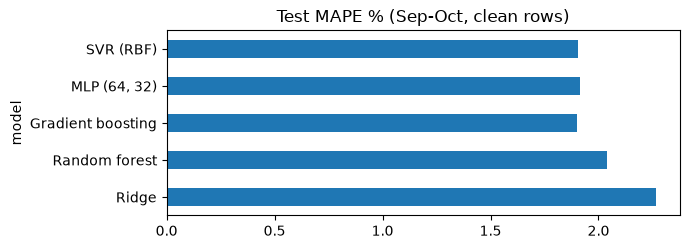

In [6]:
def with_scaling(regressor):
    pipeline = make_pipeline(RobustScaler(), regressor)
    return TransformedTargetRegressor(regressor=pipeline, transformer=StandardScaler())


MODELS = {
    'Ridge': lambda: with_scaling(Ridge(alpha=1.0)),
    'Random forest': lambda: with_scaling(
        RandomForestRegressor(n_estimators=200, min_samples_leaf=5, n_jobs=-1, random_state=0)),
    'Gradient boosting': lambda: with_scaling(
        HistGradientBoostingRegressor(max_iter=300, learning_rate=0.05, random_state=0)),
    'MLP (64, 32)': lambda: with_scaling(
        MLPRegressor(hidden_layer_sizes=(64, 32), alpha=1e-4, early_stopping=True, random_state=0)),
    'SVR (RBF)': lambda: with_scaling(SVR(kernel='rbf', C=45.5, gamma=0.031, epsilon=0.199)),
}


def fit_and_predict(make_model, fit_idx, score_idx):
    model = make_model().fit(X.iloc[fit_idx], target[fit_idx])
    return to_rate(model.predict(X.iloc[score_idx]), distance[score_idx])


results = []
test_predictions = {}
for name, make_model in MODELS.items():
    cv_scores = []
    for start, end in FOLDS:
        fit_idx = np.where(dates < np.datetime64(start))[0]
        score_idx = np.where((dates >= np.datetime64(start)) & (dates <= np.datetime64(end)))[0]
        cv_scores.append(mape(rate[score_idx], fit_and_predict(make_model, fit_idx, score_idx)))

    predicted = fit_and_predict(make_model, dev_idx, test_idx)
    test_predictions[name] = predicted
    errors = np.abs(predicted - rate[test_idx])
    results.append({'model': name,
                    'dev CV MAPE %': np.mean(cv_scores),
                    'test MAPE %': mape(rate[test_idx], predicted),
                    'test MedAPE %': np.median(errors / rate[test_idx]) * 100,
                    'test MAE $': errors.mean()})

comparison = pd.DataFrame(results).set_index('model')
display(comparison.round(3))
comparison['test MAPE %'].plot.barh(figsize=(7, 2.6), title='Test MAPE % (Sep-Oct, clean rows)')
plt.tight_layout()
plt.show()


**Reading the table.** The four non-linear models are within 0.15 points of MAPE of each other on the test months.
Ridge has a higher error (2.26%), which indicates a non-linear relation. The dev CV MAPE is about 4% for every model because the
folds contain a market swing that no date-free model can explain. The test months are the more representative measure.
Gradient boosting and the SVR are tied on test MAPE (1.901 and 1.906). The SVR has the lowest median error and gives stable predictions across the inputs.


## 5. Fixed December prediction chart

`src/train_final.py` refits the same model on all clean labeled rows, writes `validation_predictions.csv`
and fills `december-chart-inputs.csv` (Lexington to Fort Wayne, 360 miles, Dry Van, 32,000 lb).
Only the date changes. A December market level is not included, since the data covers less than one full year.
The chart below is produced by the provided `score.py`.


Validated 12,000 final predictions.
Validated 31 fixed December predictions.
Created chart: scorer_results/candidate_december.png
Final validation metrics are calculated by Spotter after submission.

December predicted rate: min 820.32, max 837.29, mean 828.49


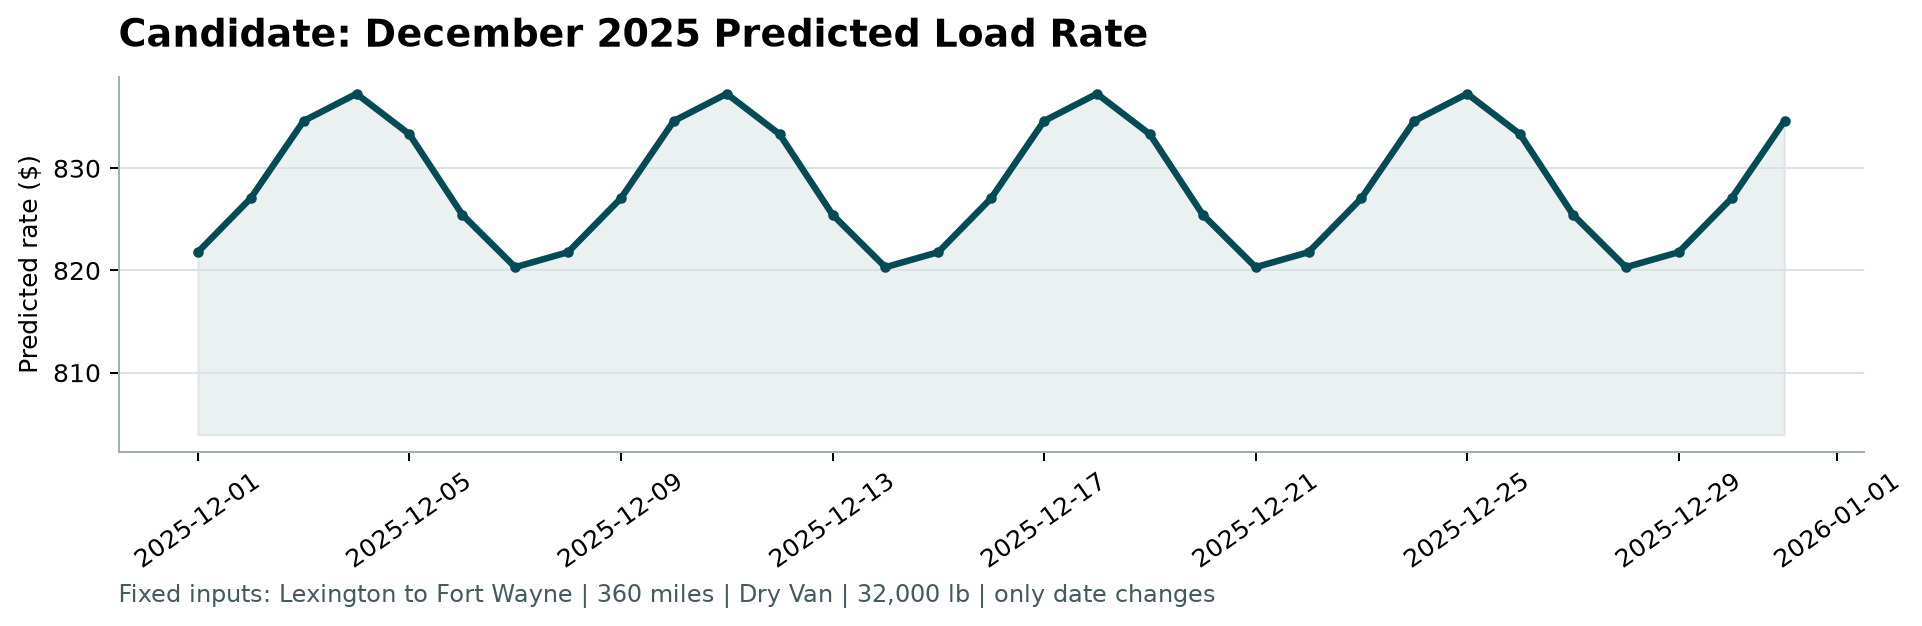

In [7]:
import subprocess

from IPython.display import Image

check = subprocess.run(
    [sys.executable, 'score.py',
     '--predictions', 'predictions/validation_predictions.csv',
     '--december-predictions', 'predictions/december-chart-inputs.csv',
     '--output-dir', 'scorer_results'],
    cwd=ROOT, capture_output=True, text=True)
print(check.stdout or check.stderr)

december = pd.read_csv(ROOT / 'predictions' / 'december-chart-inputs.csv')
print(f'December predicted rate: min {december.predicted_rate.min():.2f},',
      f'max {december.predicted_rate.max():.2f}, mean {december.predicted_rate.mean():.2f}')
display(Image(str(ROOT / 'scorer_results' / 'candidate_december.png'), width=800))

## 6. Model choice and expected error

- **SVR (RBF).** Accuracy is tied for the best (above), predictions are stable across distance and weight,
  and city coordinates allow the 8 unseen cities to be handled.
  The difference from gradient boosting and the MLP is within noise, so the choice rests on stability rather than accuracy.
- **Market columns.** They gave a lower error on a random split and a higher one on the forward split (section 3), so they were not used.
- **Expected error.** On normal loads the average miss is 1.9% of the rate (MAPE), about USD 45 on a load averaging USD 2,360. The median miss is 1.6%.
  The 1.4% of outlier rows would raise the average error computed on `validation.csv`.